<a href="https://colab.research.google.com/github/gopalgupta46300-ui/Student_performance_ML-/blob/main/Student_Performance_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Performance Analytics System

## 1. Project Overview & Documentation

### Project Title
**Student Performance Analytics System**

### Overview & Objectives
This project was developed as the final internship submission for the **EWB Tech Academy**. The objective of this system is to automate the tracking, evaluation, and analysis of student performance across different technology courses (Python, SQL, HTML/CSS). By leveraging the powerful capabilities of Python, Pandas, and NumPy, this system transforms raw tabular data into highly actionable, structured, and summarized statistical insights, which can help educators identify key academic trends, struggle areas, and high-achieving students.

### Technologies Used
*   **Python**: The foundational programming language.
*   **Pandas**: Used for data loading, transformation, manipulation, feature engineering (calculating totals, averages, grades), and structural reporting.
*   **NumPy**: Used for underlying array and scientific vectorized operations, such as logical conditions and advanced statistics.

### Dataset Description
The dataset (`students.csv`) contains 15 records with the following columns:
1.  `StudentID`: Unique string identifier for each student (e.g., STU001 to STU015).
2.  `Name`: Full name of the student.
3.  `Department`: Academic department (Computer Science, Information Technology, or Data Science).
4.  `Python`: Marks scored in Python programming (out of 100).
5.  `SQL`: Marks scored in SQL database management (out of 100).
6.  `HTML_CSS`: Marks scored in HTML & CSS web design (out of 100).
7.  `Attendance`: Overall attendance percentage (%).

---

In [1]:
import csv

# Define raw sample student data for 15 students as requested
data = [
    ["StudentID", "Name", "Department", "Python", "SQL", "HTML_CSS", "Attendance"],
    ["STU001", "Arjun Sharma", "Computer Science", 88, 92, 79, 94.5],
    ["STU002", "Priya Patel", "Information Technology", 95, 89, 91, 98.0],
    ["STU003", "Rohan Das", "Data Science", 72, 65, 80, 85.0],
    ["STU004", "Ananya Reddy", "Computer Science", 45, 52, 50, 75.0],
    ["STU005", "Vikram Singh", "Information Technology", 61, 70, 68, 88.5],
    ["STU006", "Sneha Paul", "Data Science", 99, 98, 95, 99.2],
    ["STU007", "Kabir Mehta", "Computer Science", 78, 84, 82, 91.0],
    ["STU008", "Aditi Rao", "Information Technology", 55, 48, 62, 80.0],
    ["STU009", "Rahul Verma", "Data Science", 84, 76, 89, 92.5],
    ["STU010", "Meera Nair", "Computer Science", 90, 91, 93, 96.0],
    ["STU011", "Amit Joshi", "Information Technology", 40, 42, 38, 70.0],
    ["STU012", "Kriti Sen", "Data Science", 87, 83, 85, 93.0],
    ["STU013", "Yash Gupta", "Computer Science", 66, 72, 70, 86.5],
    ["STU014", "Riya Saxena", "Information Technology", 79, 81, 88, 90.0],
    ["STU015", "Dev Bajwa", "Data Science", 35, 40, 45, 65.0]
]

# Create the CSV file containing the dataset
csv_file_path = 'students.csv'
with open(csv_file_path, mode='w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file)
    writer.writerows(data)

print(f"Successfully generated sample dataset containing 15 records at: '{csv_file_path}'")

Successfully generated sample dataset containing 15 records at: 'students.csv'


In [2]:
import pandas as pd
import numpy as np

print("=== STUDENT PERFORMANCE ANALYTICS SYSTEM ===\n")

# 1. Load the dataset using Pandas
try:
    df = pd.read_csv('students.csv')
    print("Dataset successfully loaded.\n")
except FileNotFoundError:
    print("Error: 'students.csv' file not found. Run the dataset generation cell first!")
    exit()

# 2. Display basic dataset information
print("--- Dataset Information ---")
df.info()
print("\n--- First 5 Rows of the Dataset ---")
display(df.head())
print("\n--- Last 5 Rows of the Dataset ---")
display(df.tail())

# 3. Calculate Total Marks and Average Marks for each student using Pandas/NumPy operations
subject_cols = ['Python', 'SQL', 'HTML_CSS']
df['Total_Marks'] = df[subject_cols].sum(axis=1)
df['Average_Marks'] = np.round(df[subject_cols].mean(axis=1), 2)

# 4. Assign Grades based on Average Marks
def assign_grade(avg_mark):
    if avg_mark >= 90:
        return 'A+'
    elif avg_mark >= 80:
        return 'A'
    elif avg_mark >= 70:
        return 'B'
    elif avg_mark >= 60:
        return 'C'
    elif avg_mark >= 50:
        return 'D'
    else:
        return 'F'

df['Grade'] = df['Average_Marks'].apply(assign_grade)

# 5. Determine Pass/Fail Status (Passing criteria: Avg >= 50 and individual marks >= 40 in all three subjects)
passing_condition = (
    (df['Python'] >= 40) &
    (df['SQL'] >= 40) &
    (df['HTML_CSS'] >= 40) &
    (df['Average_Marks'] >= 50)
)
df['Status'] = np.where(passing_condition, 'Pass', 'Fail')

# 6. Perform statistical operations
highest_avg = np.max(df['Average_Marks'])
top_student = df.loc[df['Average_Marks'].idxmax(), 'Name']

lowest_avg = np.min(df['Average_Marks'])
lowest_student = df.loc[df['Average_Marks'].idxmin(), 'Name']

pass_count = np.sum(df['Status'] == 'Pass')
fail_count = np.sum(df['Status'] == 'Fail')
pass_percentage = (pass_count / len(df)) * 100

print("\n--- Key Statistical Insights ---")
print(f"Highest Average Score: {highest_avg}% (Scored by: {top_student})")
print(f"Lowest Average Score:  {lowest_avg}% (Scored by: {lowest_student})")
print(f"Total Students Passed: {pass_count}")
print(f"Total Students Failed: {fail_count}")
print(f"Overall Pass Percentage: {pass_percentage:.2f}%")

# 7. Generate Subject-wise performance analysis
print("\n--- Subject-Wise Performance Analysis ---")
subject_averages = df[subject_cols].mean()
for subject, avg_val in subject_averages.items():
    print(f"Average marks in {subject}: {avg_val:.2f} / 100")

# 8. Display final complete summary report
print("\n--- Final Summary Report Table ---")
display(df[['StudentID', 'Name', 'Department', 'Python', 'SQL', 'HTML_CSS', 'Total_Marks', 'Average_Marks', 'Grade', 'Attendance', 'Status']])

=== STUDENT PERFORMANCE ANALYTICS SYSTEM ===

Dataset successfully loaded.

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   StudentID   15 non-null     object 
 1   Name        15 non-null     object 
 2   Department  15 non-null     object 
 3   Python      15 non-null     int64  
 4   SQL         15 non-null     int64  
 5   HTML_CSS    15 non-null     int64  
 6   Attendance  15 non-null     float64
dtypes: float64(1), int64(3), object(3)
memory usage: 972.0+ bytes

--- First 5 Rows of the Dataset ---


,StudentID,Name,Department,Python,SQL,HTML_CSS,Attendance
0,STU001,Arjun Sharma,Computer Science,88,92,79,94.5
1,STU002,Priya Patel,Information Technology,95,89,91,98.0
2,STU003,Rohan Das,Data Science,72,65,80,85.0
3,STU004,Ananya Reddy,Computer Science,45,52,50,75.0
4,STU005,Vikram Singh,Information Technology,61,70,68,88.5



--- Last 5 Rows of the Dataset ---


,StudentID,Name,Department,Python,SQL,HTML_CSS,Attendance
10,STU011,Amit Joshi,Information Technology,40,42,38,70.0
11,STU012,Kriti Sen,Data Science,87,83,85,93.0
12,STU013,Yash Gupta,Computer Science,66,72,70,86.5
13,STU014,Riya Saxena,Information Technology,79,81,88,90.0
14,STU015,Dev Bajwa,Data Science,35,40,45,65.0



--- Key Statistical Insights ---
Highest Average Score: 97.33% (Scored by: Sneha Paul)
Lowest Average Score:  40.0% (Scored by: Amit Joshi)
Total Students Passed: 12
Total Students Failed: 3
Overall Pass Percentage: 80.00%

--- Subject-Wise Performance Analysis ---
Average marks in Python: 71.60 / 100
Average marks in SQL: 72.20 / 100
Average marks in HTML_CSS: 74.33 / 100

--- Final Summary Report Table ---


,StudentID,Name,Department,Python,SQL,HTML_CSS,Total_Marks,Average_Marks,Grade,Attendance,Status
0,STU001,Arjun Sharma,Computer Science,88,92,79,259,86.33,A,94.5,Pass
1,STU002,Priya Patel,Information Technology,95,89,91,275,91.67,A+,98.0,Pass
2,STU003,Rohan Das,Data Science,72,65,80,217,72.33,B,85.0,Pass
3,STU004,Ananya Reddy,Computer Science,45,52,50,147,49.00,F,75.0,Fail
4,STU005,Vikram Singh,Information Technology,61,70,68,199,66.33,C,88.5,Pass
5,STU006,Sneha Paul,Data Science,99,98,95,292,97.33,A+,99.2,Pass
6,STU007,Kabir Mehta,Computer Science,78,84,82,244,81.33,A,91.0,Pass
7,STU008,Aditi Rao,Information Technology,55,48,62,165,55.00,D,80.0,Pass
8,STU009,Rahul Verma,Data Science,84,76,89,249,83.00,A,92.5,Pass
9,STU010,Meera Nair,Computer Science,90,91,93,274,91.33,A+,96.0,Pass


## 2. Advanced Performance Statistics & Visualizations
To make our analytics system comprehensive and professional, let's visualize the performance distributions across subjects and department-wise averages.

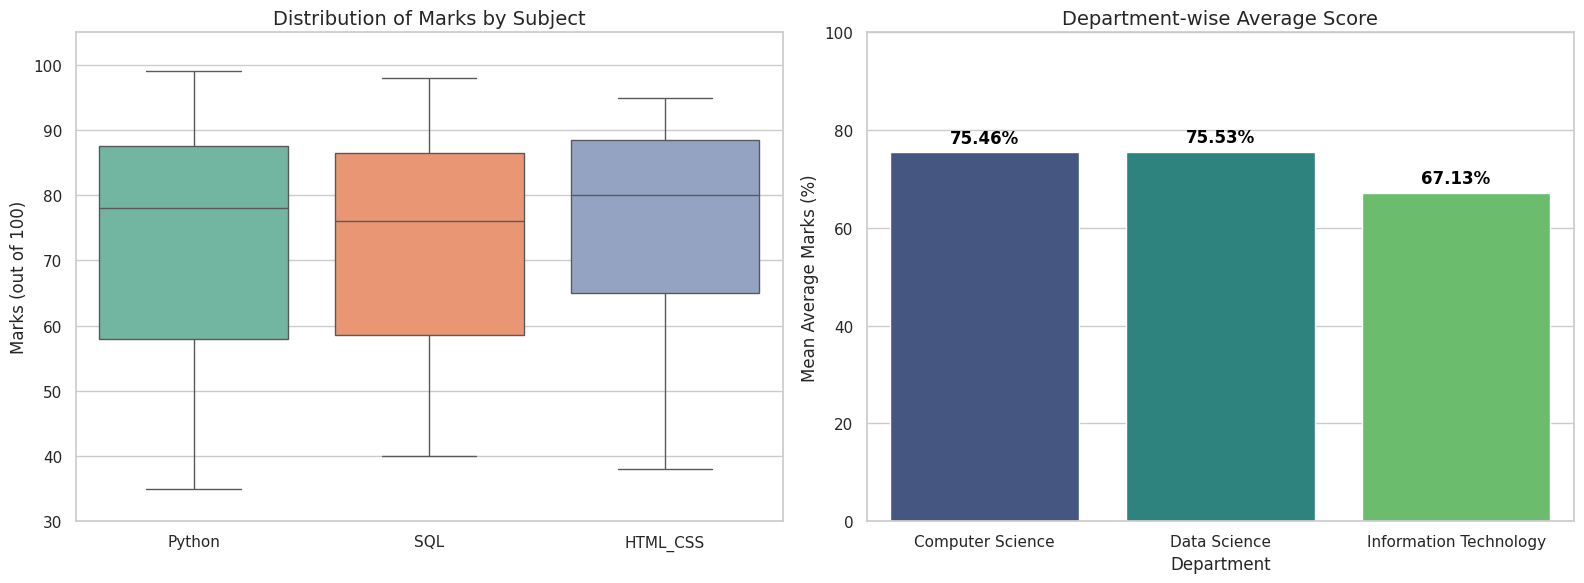

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual settings
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot of Marks Distribution by Subject
sns.boxplot(data=df[subject_cols], ax=axes[0], palette="Set2")
axes[0].set_title("Distribution of Marks by Subject", fontsize=14)
axes[0].set_ylabel("Marks (out of 100)", fontsize=12)
axes[0].set_ylim(30, 105)

# 2. Department-wise Average Performance
dept_perf = df.groupby('Department')['Average_Marks'].mean().reset_index()
sns.barplot(x='Department', y='Average_Marks', data=dept_perf, ax=axes[1], palette="viridis", hue='Department', legend=False)
axes[1].set_title("Department-wise Average Score", fontsize=14)
axes[1].set_ylabel("Mean Average Marks (%)", fontsize=12)
axes[1].set_xlabel("Department", fontsize=12)
axes[1].set_ylim(0, 100)

# Add exact value labels on top of the department bars
for index, row in dept_perf.iterrows():
    axes[1].text(index, row['Average_Marks'] + 2, f"{row['Average_Marks']:.2f}%", color='black', ha="center", fontweight='bold')

plt.tight_layout()
plt.show()